In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, roc_curve)


In [2]:
POLLUTANTS = ["pm25", "pm10"]
LAGGED_DAYS = (1, 2, 3)
ROLLING_WINDOWS = (3, 7)
TEST_FRACTION = 0.2


In [3]:
PROCESSED_DIR = Path("../data/processed")


In [4]:
def get_weather_cols(df):
    return [
        col for col in df.columns
        if (col.startswith(("temperature", "relative_humidity", "dew_point",
                            "apparent_temperature", "pressure", "surface_pressure",
                            "precipitation", "rain_sum", "snowfall", "cloud_cover",
                            "shortwave", "direct_radiation", "diffuse_radiation",
                            "global_tilted", "sunshine", "wind", "et0",
                            "weather_code", "snow_depth", "vapour_pressure", "soil_"))
            and col != "wind_category")
    ]


In [5]:
def build_feature_matrix(df, pollutant):
    lag_cols = [f"{pollutant}_lag_{d}" for d in LAGGED_DAYS]
    rolling_cols = [f"{pollutant}_rolling_{w}" for w in ROLLING_WINDOWS]
    rolling_std_cols = [f"{pollutant}_rolling_std_{w}" for w in ROLLING_WINDOWS]
    calendar_cols = ["month_sin", "month_cos", "dow_sin", "dow_cos"]
    weather_cols = get_weather_cols(df)

    base_cols = lag_cols + rolling_cols + rolling_std_cols + calendar_cols + weather_cols + ["rain_indicator", "is_weekend"]
    required = base_cols + ["date", "station_id", pollutant]

    model_df = df.dropna(subset=required).copy().reset_index(drop=True)
    model_df = model_df.sort_values("date").reset_index(drop=True)

    wind_dummies = pd.get_dummies(model_df["wind_category"], prefix="wind")
    X = pd.concat([model_df[base_cols].reset_index(drop=True), wind_dummies.reset_index(drop=True)], axis=1).astype(float)
    y = model_df[f"{pollutant}_high"].astype(int)

    return model_df, X, y


In [6]:
def chronological_split(model_df, X, y):
    split_idx = int(len(model_df) * (1 - TEST_FRACTION))

    print(f"Modelling rows: {len(model_df):,}")
    print(f"Positive (high) rate overall: {y.mean():.3f}")
    print(f"Positive rate test: {y.iloc[split_idx:].mean():.3f}")
    print(f"Train period: {model_df['date'].iloc[0].date()} .. {model_df['date'].iloc[split_idx-1].date()}")
    print(f"Test period : {model_df['date'].iloc[split_idx].date()} .. {model_df['date'].iloc[-1].date()}")

    return X.iloc[:split_idx], X.iloc[split_idx:], y.iloc[:split_idx], y.iloc[split_idx:], split_idx


In [7]:
def evaluate_classification(y_true, y_pred, y_proba):
    return {
        "Accuracy": float(accuracy_score(y_true, y_pred)),
        "Precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "Recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "F1": float(f1_score(y_true, y_pred, zero_division=0)),
        "ROC_AUC": float(roc_auc_score(y_true, y_proba)),
    }


In [8]:
data = {}

for pollutant in POLLUTANTS:
    df = pd.read_parquet(PROCESSED_DIR / f"features_{pollutant}.parquet")
    df["date"] = pd.to_datetime(df["date"])

    model_df, X, y = build_feature_matrix(df, pollutant)
    data[pollutant] = {"model_df": model_df, "X": X, "y": y}

    print(f"{pollutant.upper()}: {len(model_df):,} rows, {X.shape[1]} features, {y.mean():.3f} high-pollution rate")


PM25: 1,912 rows, 59 features, 0.336 high-pollution rate
PM10: 3,575 rows, 59 features, 0.301 high-pollution rate


In [9]:
for pollutant in POLLUTANTS:
    print(f"\n{pollutant.upper()}")

    entry = data[pollutant]
    X_train, X_test, y_train, y_test, split_idx = chronological_split(entry["model_df"], entry["X"], entry["y"])
    entry.update({"X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test, "split_idx": split_idx})



PM25
Modelling rows: 1,912
Positive (high) rate overall: 0.336
Positive rate test: 0.319
Train period: 2018-04-26 .. 2024-07-19
Test period : 2024-07-19 .. 2025-12-31

PM10
Modelling rows: 3,575
Positive (high) rate overall: 0.301
Positive rate test: 0.166
Train period: 2016-12-18 .. 2024-03-07
Test period : 2024-03-07 .. 2025-12-31


In [10]:
for pollutant in POLLUTANTS:
    entry = data[pollutant]
    scaler = StandardScaler().fit(entry["X_train"])

    entry["scaler"] = scaler
    entry["models"] = {
        "LogisticRegression": (LogisticRegression(max_iter=2000, class_weight="balanced"),
                               scaler.transform(entry["X_train"]), scaler.transform(entry["X_test"])),
        "RandomForest": (RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1, class_weight="balanced"),
                         entry["X_train"], entry["X_test"]),
        "GradientBoosting": (GradientBoostingClassifier(random_state=42),
                             entry["X_train"], entry["X_test"]),
    }


In [11]:
for pollutant in POLLUTANTS:
    entry = data[pollutant]
    y_train, y_test = entry["y_train"], entry["y_test"]

    results = {}
    predictions = {}
    probabilities = {}

    for name, (model, xtr, xte) in entry["models"].items():
        model.fit(xtr, y_train)
        pred = model.predict(xte)
        proba = model.predict_proba(xte)[:, 1]
        results[name] = evaluate_classification(y_test, pred, proba)
        predictions[name] = pred
        probabilities[name] = proba

    baseline_pred = pd.Series(y_test.mode()[0], index=y_test.index)
    results["MajorityClass"] = evaluate_classification(y_test, baseline_pred, baseline_pred.astype(float))

    entry.update({"results": results, "predictions": predictions, "probabilities": probabilities})


In [12]:
results_by_pollutant = {}

for pollutant in POLLUTANTS:
    results_df = pd.DataFrame(data[pollutant]["results"]).T
    results_by_pollutant[pollutant] = results_df.reindex(results_df["F1"].sort_values(ascending=False).index)

display(pd.concat(results_by_pollutant, names=["pollutant", "model"]).round(3))


Accuracy  Precision  Recall     F1  ROC_AUC
pollutant model                                                          
pm25      RandomForest           0.893      0.768   0.951  0.850    0.965
          LogisticRegression     0.880      0.735   0.975  0.838    0.957
          GradientBoosting       0.875      0.747   0.918  0.824    0.948
          MajorityClass          0.681      0.000   0.000  0.000    0.500
pm10      GradientBoosting       0.930      0.795   0.782  0.788    0.970
          RandomForest           0.924      0.756   0.807  0.780    0.962
          LogisticRegression     0.916      0.736   0.773  0.754    0.959
          MajorityClass          0.834      0.000   0.000  0.000    0.500

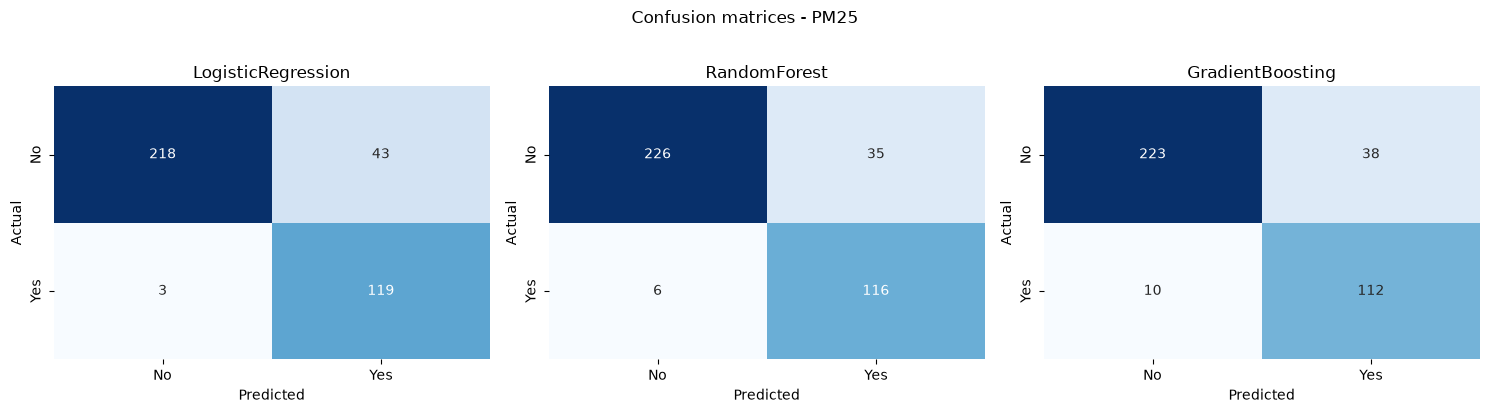

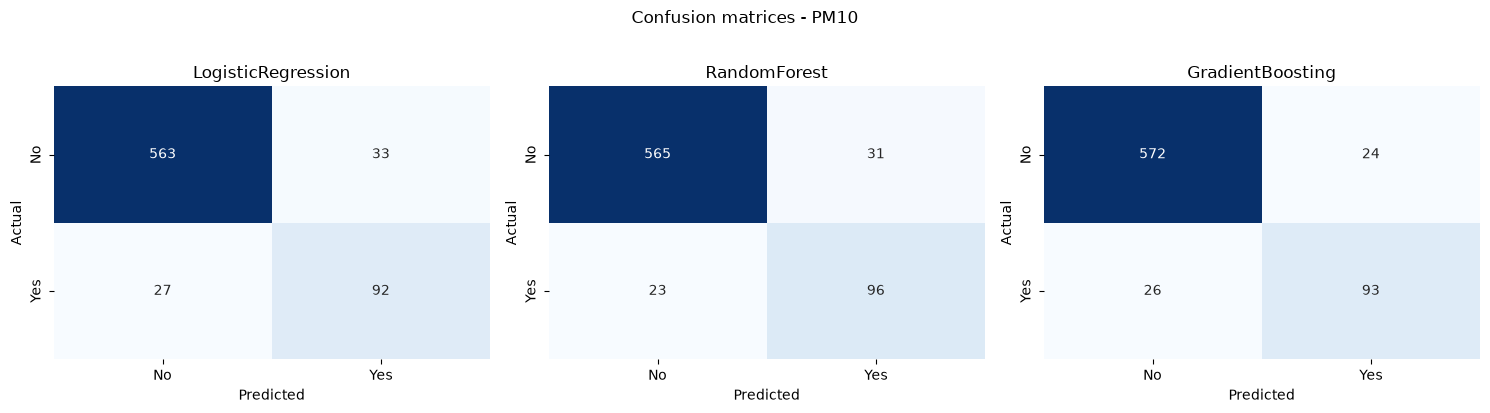

In [13]:
for pollutant in POLLUTANTS:
    entry = data[pollutant]

    fig, axes = plt.subplots(1, len(entry["models"]), figsize=(5 * len(entry["models"]), 4))

    for ax, (name, (model, _, _)) in zip(axes, entry["models"].items()):
        cm = confusion_matrix(entry["y_test"], entry["predictions"][name])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                    xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
        ax.set_title(f"{name}")
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

    plt.suptitle(f"Confusion matrices - {pollutant.upper()}", y=1.02)
    plt.tight_layout()
    plt.show()


In [14]:
comparisons = {}

for pollutant in POLLUTANTS:
    entry = data[pollutant]
    split_idx = entry["split_idx"]

    comparison = pd.DataFrame({"date": entry["model_df"]["date"].iloc[split_idx:].reset_index(drop=True),
                               "station_id": entry["model_df"]["station_id"].iloc[split_idx:].reset_index(drop=True),
                               "y_test": entry["y_test"].reset_index(drop=True)})

    for name in entry["models"]:
        comparison[name + "_pred"] = entry["predictions"][name]
        comparison[name + "_proba"] = entry["probabilities"][name]

    comparisons[pollutant] = comparison

    best_cls = results_by_pollutant[pollutant].drop(index="MajorityClass")["F1"].idxmax()
    entry["best_cls"] = best_cls

    print(f"\n{pollutant.upper()}: best classifier by F1 = {best_cls}")
    display(comparison.head(10))



PM25: best classifier by F1 = RandomForest


,date,station_id,y_test,LogisticRegression_pred,LogisticRegression_proba,RandomForest_pred,RandomForest_proba,GradientBoosting_pred,GradientBoosting_proba
0,2024-07-19,2996,0,0,0.078335,0,0.006667,0,0.020692
1,2024-07-19,2978,0,0,0.054485,0,0.000000,0,0.016232
2,2024-07-20,2976,0,0,0.077775,0,0.153333,0,0.080214
3,2024-07-20,2919,0,0,0.057657,0,0.013333,0,0.034298
4,2024-07-20,2996,0,0,0.068903,0,0.056667,0,0.035783
5,2024-07-20,2977,0,0,0.057575,0,0.006667,0,0.034298
6,2024-07-20,2978,0,0,0.042894,0,0.006667,0,0.027271
7,2024-07-21,2996,0,0,0.058602,0,0.083333,0,0.067619
8,2024-07-21,2978,0,0,0.041181,0,0.033333,0,0.028768
9,2024-07-21,2976,0,0,0.065070,0,0.153333,0,0.067619



PM10: best classifier by F1 = GradientBoosting


,date,station_id,y_test,LogisticRegression_pred,LogisticRegression_proba,RandomForest_pred,RandomForest_proba,GradientBoosting_pred,GradientBoosting_proba
0,2024-03-07,2976,0,0,0.330148,0,0.103333,0,0.133278
1,2024-03-07,2979,0,0,0.246822,0,0.066667,0,0.085119
2,2024-03-08,2919,0,0,0.063088,0,0.203333,0,0.041769
3,2024-03-08,2979,0,0,0.101292,0,0.273333,0,0.056155
4,2024-03-08,2976,0,0,0.135827,0,0.323333,0,0.113504
5,2024-03-09,2976,0,0,0.380750,0,0.306667,0,0.120467
6,2024-03-09,2919,0,0,0.204201,0,0.236667,0,0.048800
7,2024-03-09,2979,0,0,0.302480,0,0.263333,0,0.068396
8,2024-03-10,2919,0,0,0.040479,0,0.120000,0,0.037234
9,2024-03-10,2976,0,0,0.059056,0,0.150000,0,0.044958


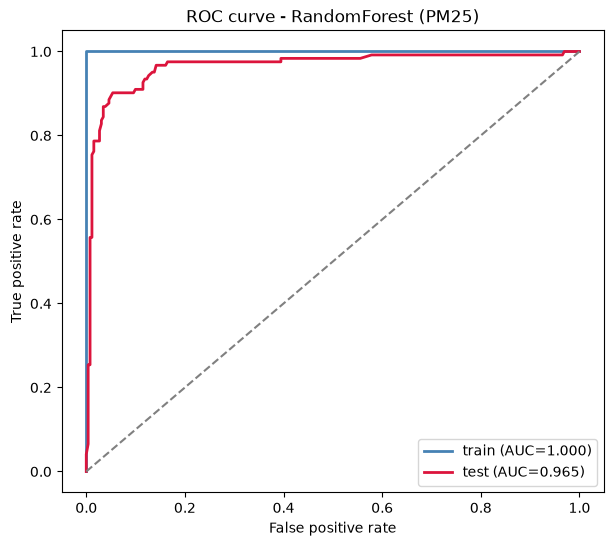

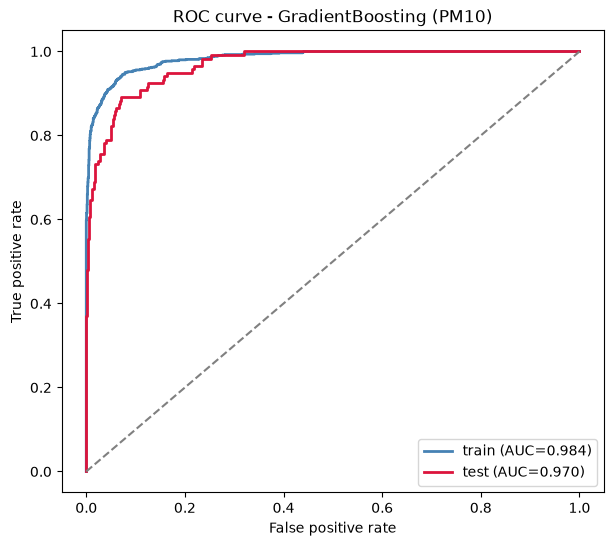

In [15]:
for pollutant in POLLUTANTS:
    entry = data[pollutant]
    best_cls = entry["best_cls"]
    model, xtr, _ = entry["models"][best_cls]

    proba_train = model.predict_proba(xtr)[:, 1]
    proba_test = entry["probabilities"][best_cls]

    _, ax = plt.subplots(figsize=(7, 6))
    for label, proba, y_true, color in [("train", proba_train, entry["y_train"], "steelblue"),
                                        ("test", proba_test, entry["y_test"], "crimson")]:
        fpr, tpr, _ = roc_curve(y_true, proba)
        ax.plot(fpr, tpr, label=f"{label} (AUC={roc_auc_score(y_true, proba):.3f})",
                color=color, linewidth=2)

    ax.plot([0, 1], [0, 1], "--", color="grey")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_title(f"ROC curve - {best_cls} ({pollutant.upper()})")
    ax.legend()
    plt.show()



PM25 (RandomForest)


,feature,importance
0,pm25_lag_1,0.151114
4,pm25_rolling_7,0.089534
3,pm25_rolling_3,0.080482
6,pm25_rolling_std_7,0.049720
1,pm25_lag_2,0.046958
2,pm25_lag_3,0.035754
5,pm25_rolling_std_3,0.024863
32,diffuse_radiation_sum,0.022738
47,soil_temperature_7_to_28cm_mean,0.021221
53,soil_moisture_100_to_255cm_mean,0.020216


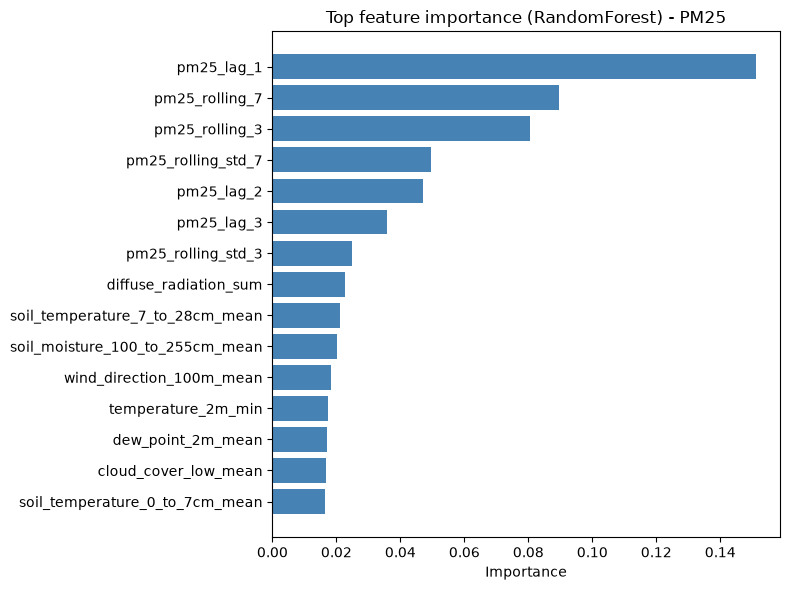


PM10 (GradientBoosting)


,feature,importance
0,pm10_lag_1,0.486663
46,soil_temperature_0_to_7cm_mean,0.069790
41,wind_direction_100m_mean,0.063777
28,cloud_cover_mid_mean,0.054802
39,wind_gusts_10m_max,0.051336
4,pm10_rolling_7,0.046374
27,cloud_cover_low_mean,0.035737
38,wind_speed_100m_max,0.020815
47,soil_temperature_7_to_28cm_mean,0.014487
2,pm10_lag_3,0.014410


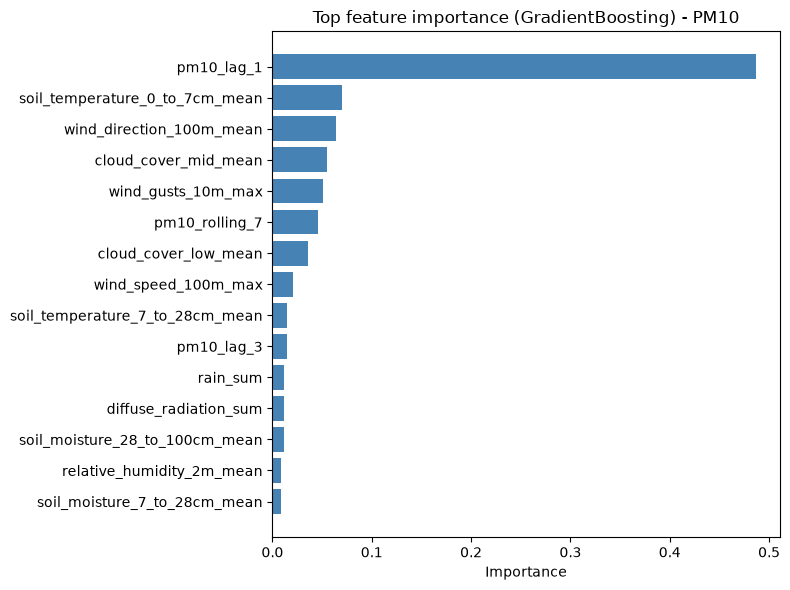

In [16]:
for pollutant in POLLUTANTS:
    entry = data[pollutant]
    best_cls_model = entry["models"][entry["best_cls"]][0]

    if hasattr(best_cls_model, "feature_importances_"):
        importance = best_cls_model.feature_importances_
    else:
        importance = np.abs(best_cls_model.coef_)

    entry["importance"] = importance

    imp_df = pd.DataFrame({"feature": entry["X"].columns, "importance": importance}).sort_values("importance", ascending=False)

    print(f"\n{pollutant.upper()} ({entry['best_cls']})")
    display(imp_df.head(15))

    plt.figure(figsize=(8, 6))
    plot_df = imp_df.head(15).iloc[::-1]
    plt.barh(plot_df["feature"], plot_df["importance"], color="steelblue")
    plt.xlabel("Importance")
    plt.title(f"Top feature importance ({entry['best_cls']}) - {pollutant.upper()}")
    plt.tight_layout()
    plt.show()


Most of the features shown here are the lag features, lets try to group them

In [17]:
def get_factor_groups(pollutant, feature_names):
    return {
        "Previous pollution (lag)": [f"{pollutant}_lag_{d}" for d in LAGGED_DAYS],
        "Previous pollution (rolling)": [f"{pollutant}_rolling_{w}" for w in ROLLING_WINDOWS] + [f"{pollutant}_rolling_std_{w}" for w in ROLLING_WINDOWS],
        "Temperature": [c for c in feature_names if "temperature" in c or "dew_point" in c],
        "Humidity": [c for c in feature_names if "humidity" in c or "vapour_pressure" in c],
        "Wind": [c for c in feature_names if "wind" in c and "category" not in c] + [c for c in feature_names if c.startswith("wind_")],
        "Precipitation": [c for c in feature_names if "precip" in c or "rain" in c or "snowfall" in c or "snow_depth" in c],
        "Pressure": [c for c in feature_names if "pressure" in c],
        "Clouds & radiation": [c for c in feature_names if "cloud" in c or "radiation" in c or "sunshine" in c or "et0" in c],
        "Season / calendar": [c for c in feature_names if "month" in c or "dow" in c or "weekend" in c],
        "Soil": [c for c in feature_names if c.startswith("soil")],
        "Wind category": [c for c in feature_names if c.startswith("wind_weak") or c.startswith("wind_moderate") or c.startswith("wind_strong")],
        "Weather code": [c for c in feature_names if "weather_code" in c],
    }


In [18]:
def group_importance(importance, feature_names, factor_groups):
    factor_importance = []

    for factor, cols in factor_groups.items():
        present = [c for c in cols if c in feature_names]
        if not present:
            continue

        vals = [importance[feature_names.index(c)] for c in present]
        factor_importance.append({
            "factor": factor,
            "n_features": len(present),
            "importance_max": float(np.max(vals)),
            "importance_mean": float(np.mean(vals)),
        })

    return pd.DataFrame(factor_importance).sort_values("importance_mean", ascending=False)


In [19]:
factor_tables = {}

for pollutant in POLLUTANTS:
    entry = data[pollutant]
    feature_names = list(entry["X"].columns)
    factor_df = group_importance(entry["importance"], feature_names, get_factor_groups(pollutant, feature_names))
    factor_tables[pollutant] = factor_df

    print(f"\n{pollutant.upper()} ({entry['best_cls']})")
    display(factor_df.round(4))



PM25 (RandomForest)


,factor,n_features,importance_max,importance_mean
0,Previous pollution (lag),3,0.1511,0.0779
1,Previous pollution (rolling),4,0.0895,0.0611
9,Soil,8,0.0212,0.0154
2,Temperature,9,0.0212,0.0148
7,Clouds & radiation,9,0.0227,0.0129
3,Humidity,4,0.0104,0.0094
6,Pressure,5,0.0101,0.0088
4,Wind,20,0.0184,0.0080
8,Season / calendar,5,0.0142,0.0049
5,Precipitation,5,0.0076,0.0043



PM10 (GradientBoosting)


,factor,n_features,importance_max,importance_mean
0,Previous pollution (lag),3,0.4867,0.1674
1,Previous pollution (rolling),4,0.0464,0.0166
4,Wind,20,0.0638,0.0150
9,Soil,8,0.0698,0.0138
7,Clouds & radiation,9,0.0548,0.0125
2,Temperature,9,0.0698,0.0113
3,Humidity,4,0.0090,0.0054
5,Precipitation,5,0.0118,0.0031
6,Pressure,5,0.0043,0.0016
8,Season / calendar,5,0.0008,0.0002


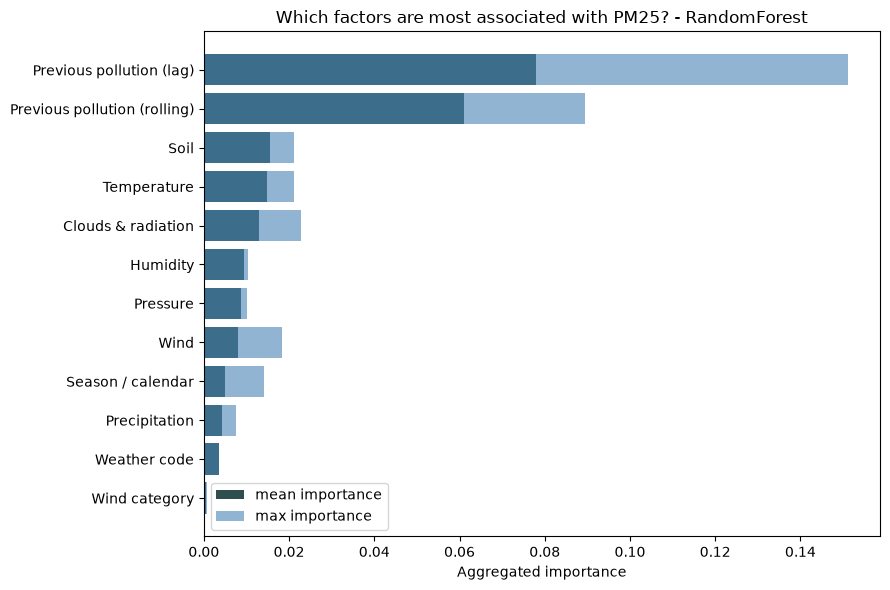

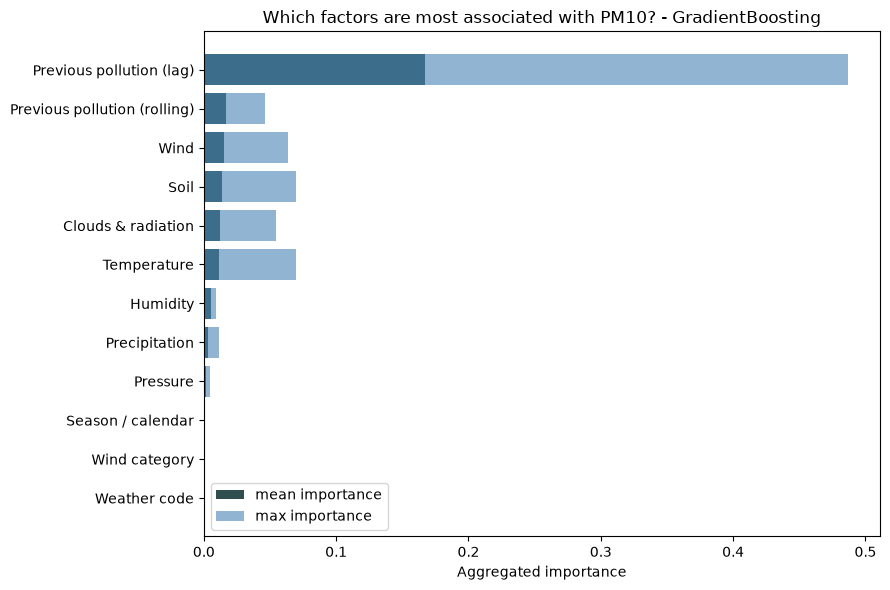

In [20]:
for pollutant in POLLUTANTS:
    entry = data[pollutant]
    factor_df = factor_tables[pollutant]

    plt.figure(figsize=(9, 6))
    plot_df = factor_df.iloc[::-1]
    plt.barh(plot_df["factor"], plot_df["importance_mean"], color="darkslategray", label="mean importance")
    plt.barh(plot_df["factor"], plot_df["importance_max"], color="steelblue", alpha=0.6, label="max importance")
    plt.xlabel("Aggregated importance")
    plt.title(f"Which factors are most associated with {pollutant.upper()}? - {entry['best_cls']}")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [21]:
for pollutant in POLLUTANTS:
    entry = data[pollutant]
    split_idx = entry["split_idx"]

    METRICS_OUT = PROCESSED_DIR / f"classification_metrics_{pollutant}.parquet"
    PRED_OUT = PROCESSED_DIR / f"classification_predictions_{pollutant}.parquet"
    PROBA_OUT = PROCESSED_DIR / f"classification_probabilities_{pollutant}.parquet"

    results_by_pollutant[pollutant].to_parquet(METRICS_OUT)
    comparisons[pollutant].to_parquet(PRED_OUT, index=False)

    proba_df = pd.DataFrame(entry["probabilities"])
    proba_df["date"] = entry["model_df"]["date"].iloc[split_idx:].reset_index(drop=True)
    proba_df["station_id"] = entry["model_df"]["station_id"].iloc[split_idx:].reset_index(drop=True)
    proba_df.to_parquet(PROBA_OUT, index=False)

    print(f"Saved: {METRICS_OUT.name}")
    print(f"Saved: {PRED_OUT.name}")
    print(f"Saved: {PROBA_OUT.name}")


Saved: classification_metrics_pm25.parquet
Saved: classification_predictions_pm25.parquet
Saved: classification_probabilities_pm25.parquet
Saved: classification_metrics_pm10.parquet
Saved: classification_predictions_pm10.parquet
Saved: classification_probabilities_pm10.parquet
